In [1]:
import glob, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
sns.set_theme(style="whitegrid")

Device : cuda


1. Chargement des données

In [3]:
def find_csv(name):
    for root in ["/kaggle/input", "/content", "."]:
        hits = glob.glob(f"{root}/**/{name}", recursive=True)
        if hits:
            return hits[0]
    import kagglehub
    path = kagglehub.dataset_download("dgawlik/nyse")
    return glob.glob(f"{path}/**/{name}", recursive=True)[0]

df = pd.read_csv(find_csv("prices-split-adjusted.csv"), parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)
df.head()

,date,symbol,open,close,low,high,volume
0,2010-01-04,SYMC,18.040001,18.400000,18.01,18.530001,8322300.0
1,2010-01-04,IFF,41.509998,42.009998,41.50,42.020000,286000.0
2,2010-01-04,ILMN,31.120001,30.549999,30.42,31.230000,1793700.0
3,2010-01-04,INTC,20.790001,20.879999,20.73,21.030001,47800900.0
4,2010-01-04,INTU,31.090000,30.809999,30.77,31.150000,2353000.0



2. Analyse exploratoire (EDA)


In [4]:
print("Dimensions :", df.shape)
print("\nPeriode :", df["date"].min().date(), "->", df["date"].max().date())
print("Nombre d'actions :", df["symbol"].nunique())
print("\nValeurs manquantes :\n", df.isna().sum())
print("\nDoublons :", df.duplicated().sum())
df.describe().T

Dimensions : (851264, 7)

Periode : 2010-01-04 -> 2016-12-30
Nombre d'actions : 501

Valeurs manquantes :
 date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64

Doublons : 0


,count,mean,min,25%,50%,75%,max,std
date,851264,2013-07-21 02:56:29.294038016,2010-01-04 00:00:00,2011-10-19 00:00:00,2013-08-02 00:00:00,2015-04-24 00:00:00,2016-12-30 00:00:00,NaN
open,851264.0,64.993618,1.66,31.27,48.459999,75.120003,1584.439941,75.203893
close,851264.0,65.011913,1.59,31.292776,48.48,75.139999,1578.130005,75.201216
low,851264.0,64.336541,1.5,30.940001,47.970001,74.400002,1549.939941,74.459518
high,851264.0,65.639748,1.81,31.620001,48.959999,75.849998,1600.930054,75.906861
volume,851264.0,5415112.640027,0.0,1221500.0,2476250.0,5222500.0,859643400.0,12494681.433084


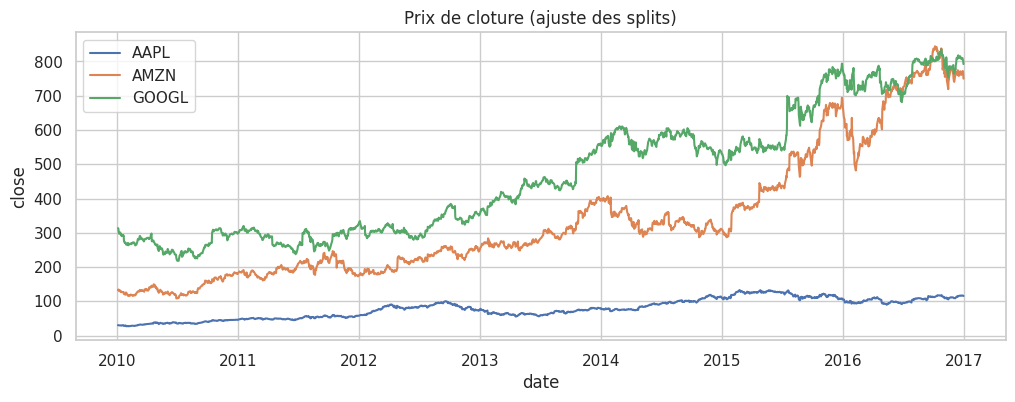

In [6]:
# Evolution du prix de cloture pour quelques actions
syms = [s for s in ["AAPL", "AMZN", "GOOGL"] if s in df["symbol"].unique()] or list(df["symbol"].unique()[:3])
plt.figure(figsize=(12, 4))
for s in syms:
    d = df[df["symbol"] == s]
    plt.plot(d["date"], d["close"], label=s)
plt.title("Prix de cloture (ajuste des splits)"); plt.xlabel("date"); plt.ylabel("close"); plt.legend(); plt.show()

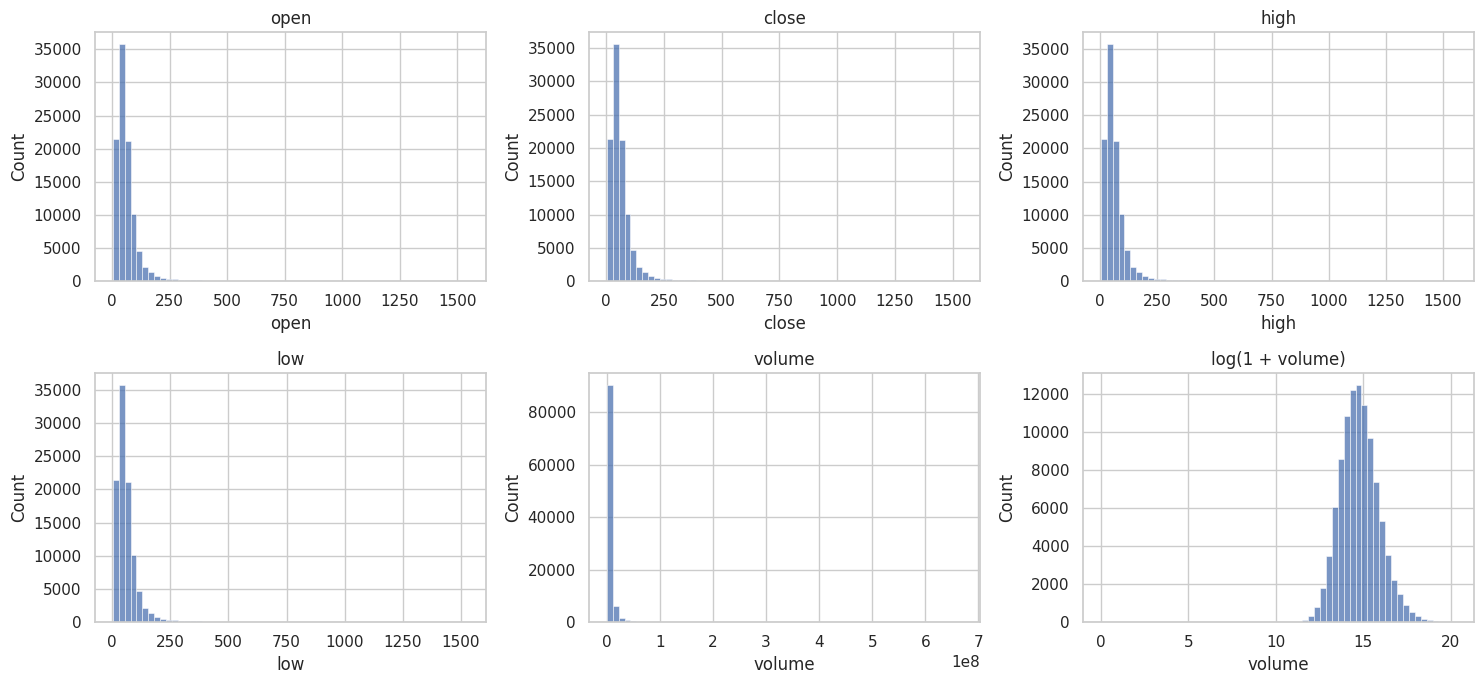

In [7]:
# Distributions (echelle brute) et effet du log sur le volume
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(ax.ravel()[:5], ["open", "close", "high", "low", "volume"]):
    sns.histplot(df[c].sample(min(len(df), 100000), random_state=0), bins=60, ax=a); a.set_title(c)
sns.histplot(np.log1p(df["volume"].sample(min(len(df), 100000), random_state=0)), bins=60, ax=ax.ravel()[5])
ax.ravel()[5].set_title("log(1 + volume)")
plt.tight_layout(); plt.show()

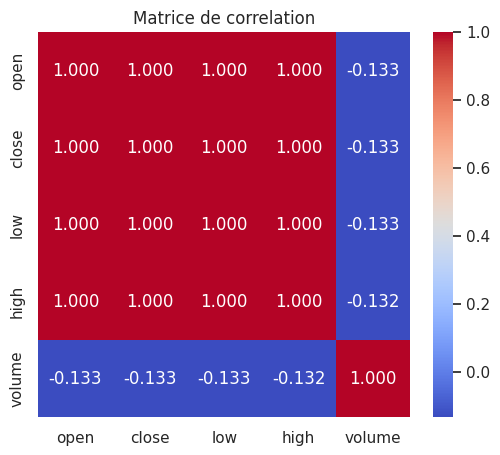

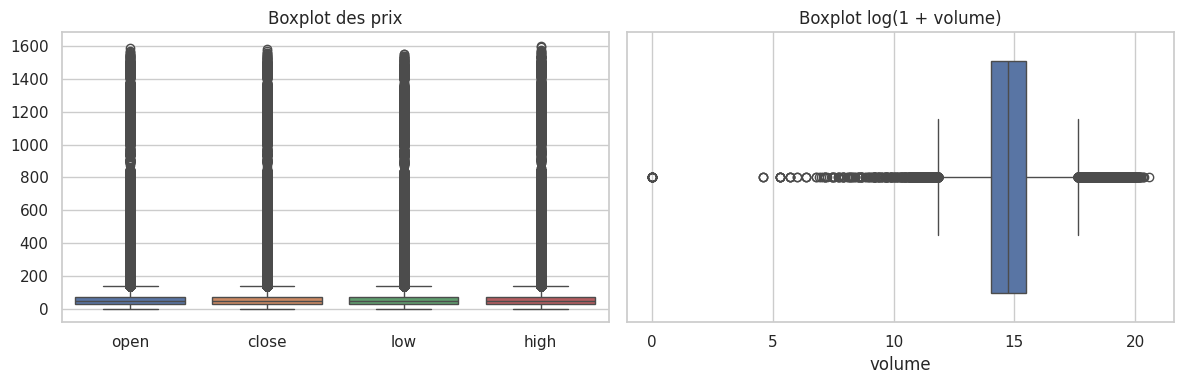

In [8]:
# Correlations et outliers
plt.figure(figsize=(6, 5))
sns.heatmap(df[["open", "close", "low", "high", "volume"]].corr(), annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Matrice de correlation"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df[["open", "close", "low", "high"]], ax=ax[0]); ax[0].set_title("Boxplot des prix")
sns.boxplot(x=np.log1p(df["volume"]), ax=ax[1]); ax[1].set_title("Boxplot log(1 + volume)")
plt.tight_layout(); plt.show()

 3. Prétraitement

In [26]:
df["log_volume"] = np.log1p(df["volume"])
FEATURES, TARGET = ["open", "low", "high", "log_volume"], "close"

n = len(df)
i_tr, i_va = int(0.70 * n), int(0.85 * n)
train, val, test = df.iloc[:i_tr], df.iloc[i_tr:i_va], df.iloc[i_va:]
print(len(train), len(val), len(test))

sx, sy = StandardScaler().fit(train[FEATURES]), StandardScaler().fit(train[[TARGET]])

def to_t(part):
    X = torch.tensor(sx.transform(part[FEATURES]), dtype=torch.float32)
    y = torch.tensor(sy.transform(part[[TARGET]]), dtype=torch.float32)
    return X, y

data = {}
for name, part in [("train", train), ("val", val), ("test", test)]:
    data[f"X_{name}"], data[f"y_{name}"] = to_t(part)

595884 127690 127690


4. Architecture du réseau (MLP PyTorch)

In [27]:
class MLP(nn.Module):
    """MLP generique : Linear -> (BatchNorm) -> ReLU -> (Dropout), repete pour chaque couche cachee."""
    def __init__(self, in_dim, out_dim, hidden=(64, 32), dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [28]:
import copy, time

def evaluate(model, X, y, criterion, task, batch=65536):
    """Retourne (loss, metrique). Metrique = R2 (regression) ou accuracy (classification)."""
    model.eval()
    total, outs = 0.0, []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            xb, yb = X[i:i + batch].to(device), y[i:i + batch].to(device)
            out = model(xb)
            total += criterion(out, yb).item() * len(xb)
            outs.append(out.cpu())
    out = torch.cat(outs)
    loss = total / len(X)
    yc = y.cpu()
    if task == "reg":
        ss_res = ((yc - out) ** 2).sum()
        ss_tot = ((yc - yc.mean()) ** 2).sum()
        metric = 1 - (ss_res / ss_tot).item()
    else:
        metric = (out.argmax(1) == yc).float().mean().item()
    return loss, metric


def fit(model, data, task, epochs=50, lr=1e-3, opt_cls=optim.Adam, batch_size=256,
        weight_decay=0.0, l1=0.0, patience=None, class_weights=None, verbose=True):
    """Boucle d'entrainement complete avec historique train/val/test.
    - weight_decay : regularisation L2
    - l1           : coefficient de la penalite L1 sur les poids des couches Linear
    - patience     : early stopping sur la loss de validation (None = desactive)
    """
    model.to(device)
    task_loss = nn.MSELoss() if task == "reg" else nn.CrossEntropyLoss(weight=class_weights)
    eval_loss = nn.MSELoss() if task == "reg" else nn.CrossEntropyLoss()
    opt = opt_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(TensorDataset(data["X_train"], data["y_train"]),
                        batch_size=batch_size, shuffle=True)
    keys = ["train_loss", "val_loss", "test_loss", "train_metric", "val_metric", "test_metric"]
    h = {k: [] for k in keys}
    best_val, best_state, wait, h["best_epoch"] = float("inf"), None, 0, epochs - 1
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = task_loss(model(xb), yb)
            if l1 > 0:
                loss = loss + l1 * sum(m.weight.abs().sum() for m in model.modules() if isinstance(m, nn.Linear))
            loss.backward()
            opt.step()
        for split in ("train", "val", "test"):
            l, m = evaluate(model, data[f"X_{split}"], data[f"y_{split}"], eval_loss, task)
            h[f"{split}_loss"].append(l)
            h[f"{split}_metric"].append(m)
        if verbose and (ep % max(1, epochs // 10) == 0 or ep == epochs - 1):
            print(f"epoch {ep+1:3d}/{epochs} | train loss {h['train_loss'][-1]:.4f} "
                  f"test loss {h['test_loss'][-1]:.4f} | train metric {h['train_metric'][-1]:.4f} "
                  f"test metric {h['test_metric'][-1]:.4f}")
        if patience is not None:
            if h["val_loss"][-1] < best_val - 1e-6:
                best_val, best_state, wait, h["best_epoch"] = h["val_loss"][-1], copy.deepcopy(model.state_dict()), 0, ep
            else:
                wait += 1
                if wait >= patience:
                    print(f"Early stopping a l'epoch {ep+1} (meilleure epoch : {h['best_epoch']+1})")
                    break
    if best_state is not None:
        model.load_state_dict(best_state)
    h["time"] = time.time() - t0
    return model, h


def plot_history(h, metric_name, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["test_loss"], label="test")
    ax[0].set_title(f"Loss / Epochs {title}"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend()
    ax[1].plot(h["train_metric"], label="train"); ax[1].plot(h["test_metric"], label="test")
    ax[1].set_title(f"{metric_name} / Epochs {title}"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel(metric_name); ax[1].legend()
    plt.tight_layout(); plt.show()


def predict(model, X, batch=65536):
    model.eval(); outs = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            outs.append(model(X[i:i + batch].to(device)).cpu())
    return torch.cat(outs)

6. Recherche d'hyperparamètres avec GridSearchCV (sklearn + skorch)

epoch   1/20 | train loss 0.0002 test loss 0.0003 | train metric 0.9998 test metric 0.9999
epoch   3/20 | train loss 0.0002 test loss 0.0003 | train metric 0.9998 test metric 0.9999
epoch   5/20 | train loss 0.0001 test loss 0.0003 | train metric 0.9999 test metric 0.9999
epoch   7/20 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch   9/20 | train loss 0.0002 test loss 0.0003 | train metric 0.9998 test metric 0.9999
epoch  11/20 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  13/20 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  15/20 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  17/20 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  19/20 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  20/20 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999

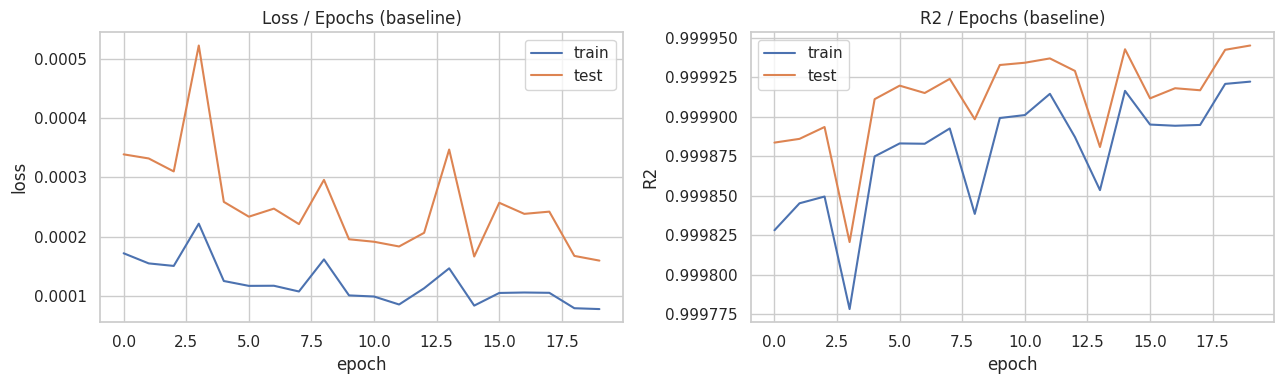

In [23]:
torch.manual_seed(SEED)
base = MLP(in_dim=len(FEATURES), out_dim=1, hidden=(64, 32))
base, h_base = fit(base, data, task="reg", epochs=20, lr=1e-3, batch_size=1024)
plot_history(h_base, "R2", "(baseline)")

In [33]:
!pip -q install skorch

In [34]:
from skorch import NeuralNetRegressor

idx = np.random.RandomState(SEED).choice(len(data["X_train"]), size=10000, replace=False)
Xg = data["X_train"][idx].numpy().astype(np.float32)
yg = data["y_train"][idx].numpy().astype(np.float32)

net = NeuralNetRegressor(
    module=MLP, module__in_dim=len(FEATURES), module__out_dim=1,
    criterion=nn.MSELoss, train_split=None, device="cpu", verbose=0,
    iterator_train__shuffle=True,
)
param_grid = {
    "lr": [1e-2, 1e-3],
    "optimizer": [optim.Adam, optim.SGD],
    "max_epochs": [20],
    "module__hidden": [(32,), (64, 32), (128, 64, 32)],
    "batch_size": [128],
}
gs = GridSearchCV(net, param_grid, cv=3, scoring="neg_mean_squared_error", n_jobs=1, verbose=3)
gs.fit(Xg, yg)
print("Meilleurs parametres :", gs.best_params_)
print("Meilleur score (neg MSE) :", gs.best_score_)
pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score", "rank_test_score"]].head(10)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
[CV 1/3] END batch_size=128, lr=0.01, max_epochs=20, module__hidden=(32,), optimizer=<class 'torch.optim.adam.Adam'>;, score=-0.000 total time=   2.2s
[CV 2/3] END batch_size=128, lr=0.01, max_epochs=20, module__hidden=(32,), optimizer=<class 'torch.optim.adam.Adam'>;, score=-0.000 total time=   2.1s
[CV 3/3] END batch_size=128, lr=0.01, max_epochs=20, module__hidden=(32,), optimizer=<class 'torch.optim.adam.Adam'>;, score=-0.000 total time=   2.1s
[CV 1/3] END batch_size=128, lr=0.01, max_epochs=20, module__hidden=(32,), optimizer=<class 'torch.optim.sgd.SGD'>;, score=-0.002 total time=   1.9s
[CV 2/3] END batch_size=128, lr=0.01, max_epochs=20, module__hidden=(32,), optimizer=<class 'torch.optim.sgd.SGD'>;, score=-0.001 total time=   1.9s
[CV 3/3] END batch_size=128, lr=0.01, max_epochs=20, module__hidden=(32,), optimizer=<class 'torch.optim.sgd.SGD'>;, score=-0.001 total time=   1.9s
[CV 1/3] END batch_size=128, lr=0.01, m

,params,mean_test_score,rank_test_score
8,"{'batch_size': 128, 'lr': 0.001, 'max_epochs':...",-0.000194,1
0,"{'batch_size': 128, 'lr': 0.01, 'max_epochs': ...",-0.000271,2
10,"{'batch_size': 128, 'lr': 0.001, 'max_epochs':...",-0.000320,3
6,"{'batch_size': 128, 'lr': 0.001, 'max_epochs':...",-0.000377,4
3,"{'batch_size': 128, 'lr': 0.01, 'max_epochs': ...",-0.000645,5
5,"{'batch_size': 128, 'lr': 0.01, 'max_epochs': ...",-0.000755,6
1,"{'batch_size': 128, 'lr': 0.01, 'max_epochs': ...",-0.001140,7
4,"{'batch_size': 128, 'lr': 0.01, 'max_epochs': ...",-0.006359,8
2,"{'batch_size': 128, 'lr': 0.01, 'max_epochs': ...",-0.008428,9
9,"{'batch_size': 128, 'lr': 0.001, 'max_epochs':...",-0.013875,10


7. Modèle final avec les meilleurs hyperparamètres : courbes Loss/Epochs et R²/Epochs

epoch   1/40 | train loss 0.0002 test loss 0.0003 | train metric 0.9998 test metric 0.9999
epoch   5/40 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch   9/40 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  13/40 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  17/40 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  21/40 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  25/40 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  29/40 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  33/40 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  37/40 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999
epoch  40/40 | train loss 0.0001 test loss 0.0002 | train metric 0.9999 test metric 0.9999

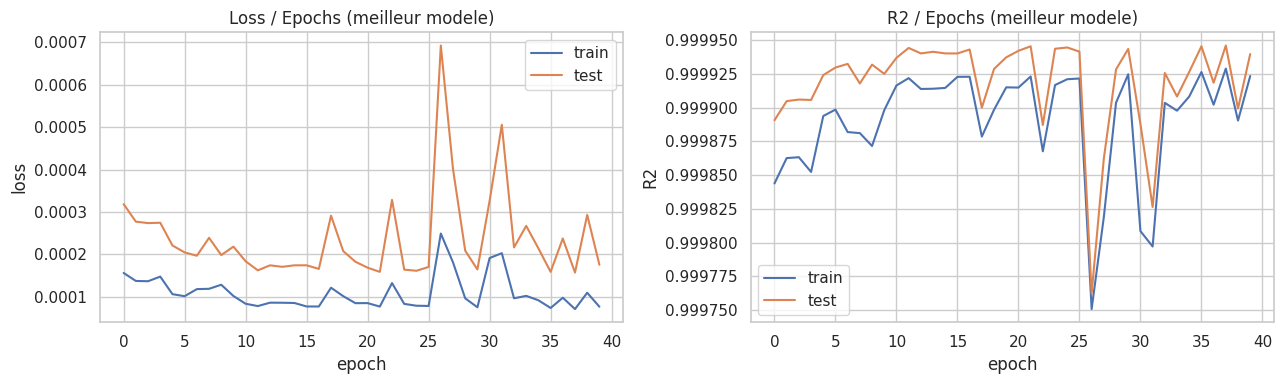

In [35]:
bp = gs.best_params_
torch.manual_seed(SEED)
best = MLP(in_dim=len(FEATURES), out_dim=1, hidden=bp["module__hidden"])
best, h_best = fit(best, data, task="reg", epochs=bp["max_epochs"] * 2, lr=bp["lr"],
                   opt_cls=bp["optimizer"], batch_size=bp["batch_size"] * 4)
plot_history(h_best, "R2", "(meilleur modele)")

--- Meilleur modele ---


,MSE,RMSE,MAE,R2,Accuracy (tol. 5%)
train,0.280075,0.529221,0.287943,0.999923,0.999121
val,0.687198,0.828974,0.412734,0.999923,0.999248
test,0.642345,0.801464,0.401991,0.999940,0.998567


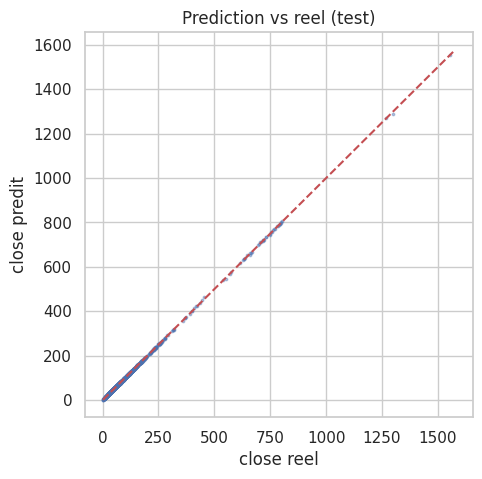

In [36]:
def reg_report(model, name):
    rows = {}
    for split in ("train", "val", "test"):
        pred = sy.inverse_transform(predict(model, data[f"X_{split}"]).numpy()).ravel()
        true = sy.inverse_transform(data[f"y_{split}"].numpy()).ravel()
        rows[split] = {
            "MSE": mean_squared_error(true, pred), "RMSE": np.sqrt(mean_squared_error(true, pred)),
            "MAE": mean_absolute_error(true, pred), "R2": r2_score(true, pred),
            "Accuracy (tol. 5%)": float(np.mean(np.abs(pred - true) / np.abs(true) < 0.05)),
        }
    print(f"--- {name} ---")
    return pd.DataFrame(rows).T

display(reg_report(best, "Meilleur modele"))

# Prediction vs reel (test)
pred = sy.inverse_transform(predict(best, data["X_test"]).numpy()).ravel()
true = sy.inverse_transform(data["y_test"].numpy()).ravel()
plt.figure(figsize=(5, 5)); plt.scatter(true[::50], pred[::50], s=3, alpha=.4)
lim = [true.min(), true.max()]; plt.plot(lim, lim, "r--")
plt.xlabel("close reel"); plt.ylabel("close predit"); plt.title("Prediction vs reel (test)"); plt.show()

8. Techniques de régularisation et comparaison

In [37]:
EPOCHS, LR, OPT, BS, HID = bp["max_epochs"] * 2, bp["lr"], bp["optimizer"], bp["batch_size"] * 4, bp["module__hidden"]
configs = {
    "Baseline (meilleur GS)": dict(),
    "Dropout 0.3": dict(model=dict(dropout=0.3)),
    "L2 (wd=1e-3)": dict(fit=dict(weight_decay=1e-3)),
    "L1 (1e-5)": dict(fit=dict(l1=1e-5)),
    "BatchNorm": dict(model=dict(batchnorm=True)),
    "Early stopping (p=5)": dict(fit=dict(patience=5)),
    "Dropout+L2+ES": dict(model=dict(dropout=0.2), fit=dict(weight_decay=1e-4, patience=5)),
}
results, histories = [], {}
for name, cfg in configs.items():
    torch.manual_seed(SEED)
    m = MLP(in_dim=len(FEATURES), out_dim=1, hidden=HID, **cfg.get("model", {}))
    m, h = fit(m, data, task="reg", epochs=EPOCHS, lr=LR, opt_cls=OPT, batch_size=BS, verbose=False, **cfg.get("fit", {}))
    rep = reg_report(m, name)
    histories[name] = h
    results.append({"Modele": name, "RMSE test ($)": rep.loc["test", "RMSE"], "R2 train": rep.loc["train", "R2"],
                    "R2 test": rep.loc["test", "R2"], "Ecart R2 (train-test)": rep.loc["train", "R2"] - rep.loc["test", "R2"],
                    "Epochs effectuees": len(h["train_loss"]), "Temps (s)": h["time"]})
comparison = pd.DataFrame(results).set_index("Modele")
comparison.round(5)

--- Baseline (meilleur GS) ---
--- Dropout 0.3 ---
--- L2 (wd=1e-3) ---
--- L1 (1e-5) ---
--- BatchNorm ---
Early stopping a l'epoch 17 (meilleure epoch : 12)
--- Early stopping (p=5) ---
Early stopping a l'epoch 11 (meilleure epoch : 6)
--- Dropout+L2+ES ---


,RMSE test ($),R2 train,R2 test,Ecart R2 (train-test),Epochs effectuees,Temps (s)
Modele,,,,,,
Baseline (meilleur GS),0.80146,0.99992,0.99994,-0.00002,40,202.46969
Dropout 0.3,3.36897,0.99708,0.99894,-0.00186,40,215.47186
L2 (wd=1e-3),1.12023,0.99981,0.99988,-0.00007,40,227.01284
L1 (1e-5),0.85650,0.99991,0.99993,-0.00002,40,229.65381
BatchNorm,1.79127,0.99945,0.99970,-0.00025,40,223.84504
Early stopping (p=5),0.77078,0.99992,0.99994,-0.00002,17,87.80343
Dropout+L2+ES,2.19899,0.99820,0.99955,-0.00135,11,58.84521


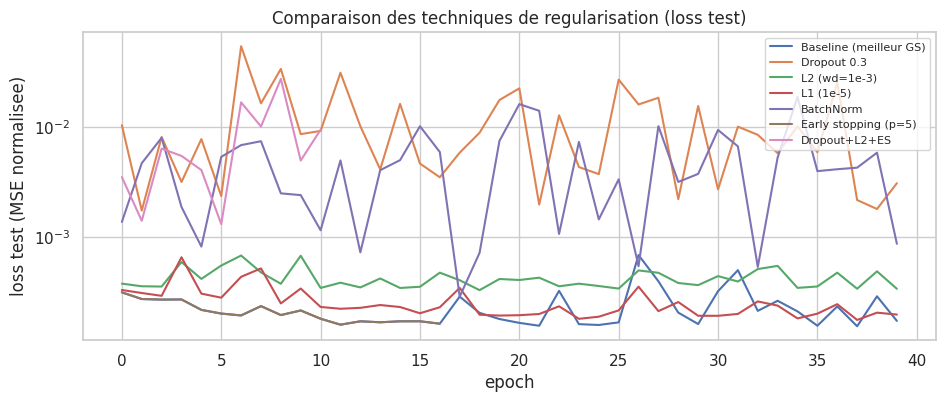

In [38]:
plt.figure(figsize=(11, 4))
for name, h in histories.items():
    plt.plot(h["test_loss"], label=name)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("loss test (MSE normalisee)")
plt.title("Comparaison des techniques de regularisation (loss test)"); plt.legend(fontsize=8); plt.show()